In [1]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import glob

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load dataset
# Works on Kaggle as well as on a local machine (data.csv in the same folder)

kaggle_path = '/kaggle/input/datasets/dikshanta/datanew/data.csv'

file_path = kaggle_path if os.path.exists(kaggle_path) else 'data.csv'

df = pd.read_csv(file_path, encoding='ISO-8859-1')

print("Dataset loaded successfully from:", file_path)

Dataset loaded successfully from: data.csv


In [3]:
# ==========================================
# STEP 2: LOAD DATASET
# ==========================================

df = pd.read_csv(file_path, encoding='ISO-8859-1')

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

df.head()

Dataset loaded successfully!
Shape of dataset: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [4]:
# Check column names
print("Columns in dataset:")
print(df.columns.tolist())

Columns in dataset:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [5]:
# Statistical summary
df.describe(include='all')

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900,4070,4223,NaN,23260,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,10/31/2011 14:41,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,1114,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,NaN,4.611114,15287.690570,NaN
std,NaN,NaN,NaN,218.081158,NaN,96.759853,1713.600303,NaN
min,NaN,NaN,NaN,-80995.000000,NaN,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,NaN,4.130000,16791.000000,NaN


In [6]:
print("First 5 records:")
display(df.head())

print("Last 5 records:")
display(df.tail())

First 5 records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


Last 5 records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/2011 12:50,4.95,12680.0,France


In [7]:
rows, columns = df.shape

print("Total Rows:", rows)
print("Total Columns:", columns)

Total Rows: 541909
Total Columns: 8


In [8]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

Missing values in each column:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

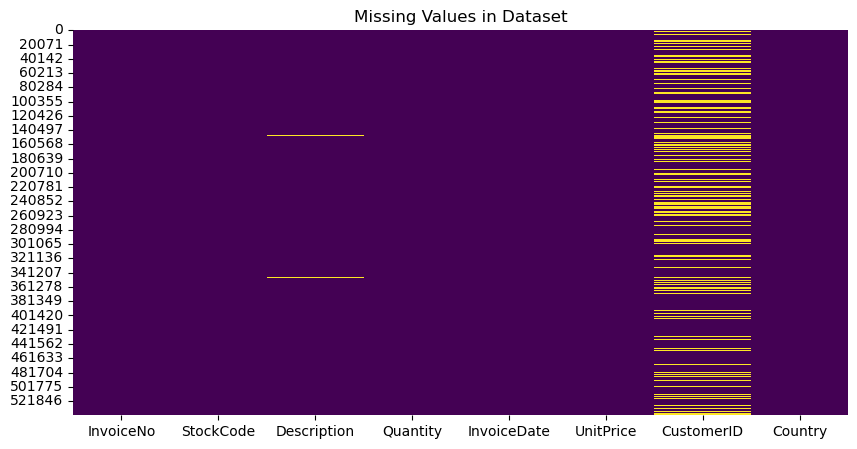

In [9]:
plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(), 
            cbar=False, 
            cmap='viridis')

plt.title("Missing Values in Dataset")
plt.show()

In [10]:
duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

Total duplicate records: 5268


In [11]:
df[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


In [12]:
print("Unique Customers:", df['CustomerID'].nunique())
print("Unique Products:", df['StockCode'].nunique())
print("Unique Countries:", df['Country'].nunique())
print("Unique Invoices:", df['InvoiceNo'].nunique())

Unique Customers: 4372
Unique Products: 4070
Unique Countries: 38
Unique Invoices: 25900


In [13]:
# Create a copy of original dataset
df_clean = df.copy()

print("Working copy created.")

Working copy created.


In [14]:
df_clean.columns = df_clean.columns.str.strip()

print(df_clean.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [15]:
before_duplicates = len(df_clean)

df_clean = df_clean.drop_duplicates()

after_duplicates = len(df_clean)

print("Records before removing duplicates:", before_duplicates)
print("Records after removing duplicates:", after_duplicates)
print("Duplicates removed:", before_duplicates - after_duplicates)

Records before removing duplicates: 541909
Records after removing duplicates: 536641
Duplicates removed: 5268


In [16]:
print("Missing values before handling:")
display(df_clean.isnull().sum())

Missing values before handling:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

In [17]:
# Remove missing StockCode
df_clean = df_clean.dropna(subset=['StockCode'])

# Fill missing descriptions
df_clean['Description'] = df_clean['Description'].fillna('Unknown Product')

# Fill missing country
df_clean['Country'] = df_clean['Country'].fillna('Unknown Country')

print("Missing values handled.")

Missing values handled.


In [18]:
# CustomerID can contain missing values, so use nullable integer
df_clean['CustomerID'] = pd.to_numeric(
    df_clean['CustomerID'], errors='coerce'
).astype('Int64')

# Quantity
df_clean['Quantity'] = pd.to_numeric(
    df_clean['Quantity'], errors='coerce'
)

# Unit price
df_clean['UnitPrice'] = pd.to_numeric(
    df_clean['UnitPrice'], errors='coerce'
)

# Invoice date
df_clean['InvoiceDate'] = pd.to_datetime(
    df_clean['InvoiceDate'], errors='coerce'
)

print(df_clean.dtypes)

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              Int64
Country                object
dtype: object


In [19]:
df_clean = df_clean.dropna(subset=['InvoiceDate'])

print("Invalid dates removed.")

Invalid dates removed.


In [20]:
df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str)

df_clean['IsCancelled'] = df_clean['InvoiceNo'].str.startswith('C')

print("Cancelled transactions:", df_clean['IsCancelled'].sum())
print("Normal transactions:", (~df_clean['IsCancelled']).sum())

Cancelled transactions: 9251
Normal transactions: 527390


In [21]:
df_sales = df_clean[
    (df_clean['IsCancelled'] == False) &
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice'] > 0)
].copy()

print("Sales dataset created.")
print("Original records:", len(df_clean))
print("Valid sales records:", len(df_sales))

Sales dataset created.
Original records: 536641
Valid sales records: 524878


In [22]:
# Outlier detection in UnitPrice

Q1 = df_sales['UnitPrice'].quantile(0.25)
Q3 = df_sales['UnitPrice'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_sales['PriceOutlier'] = (
    (df_sales['UnitPrice'] < lower_bound) |
    (df_sales['UnitPrice'] > upper_bound)
)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("Price outliers detected:", df_sales['PriceOutlier'].sum())

Q1: 1.25
Q3: 4.13
IQR: 2.88
Lower Bound: -3.0700000000000003
Upper Bound: 8.45
Price outliers detected: 37827


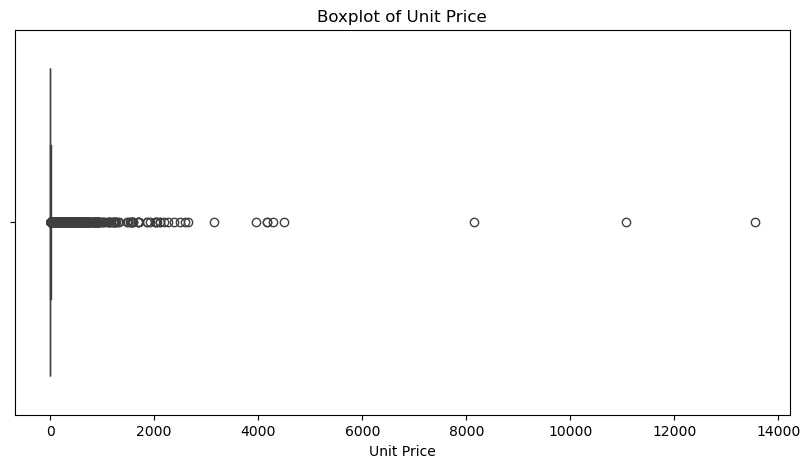

In [23]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_sales['UnitPrice'])

plt.title("Boxplot of Unit Price")
plt.xlabel("Unit Price")
plt.show()

**Data Integration**


In [24]:
customer_data = df_sales[
    ['CustomerID', 'Country']
].drop_duplicates()

customer_data = customer_data.dropna(subset=['CustomerID'])

# Keep one row per customer so the merge does not create extra rows
customer_data = customer_data.drop_duplicates(subset=['CustomerID'])

customer_data.head()

,CustomerID,Country
0,17850,United Kingdom
9,13047,United Kingdom
26,12583,France
46,13748,United Kingdom
65,15100,United Kingdom


In [25]:
product_data = df_sales[
    ['StockCode', 'Description', 'UnitPrice']
].drop_duplicates(subset=['StockCode'])

product_data.head()

,StockCode,Description,UnitPrice
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2.55
1,71053,WHITE METAL LANTERN,3.39
2,84406B,CREAM CUPID HEARTS COAT HANGER,2.75
3,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,3.39
4,84029E,RED WOOLLY HOTTIE WHITE HEART.,3.39


In [26]:
product_data = df_sales[
    ['StockCode', 'Description', 'UnitPrice']
].drop_duplicates(subset=['StockCode'])

product_data.head()

,StockCode,Description,UnitPrice
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2.55
1,71053,WHITE METAL LANTERN,3.39
2,84406B,CREAM CUPID HEARTS COAT HANGER,2.75
3,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,3.39
4,84029E,RED WOOLLY HOTTIE WHITE HEART.,3.39


In [27]:
integrated_data = pd.merge(
    df_sales,
    customer_data,
    on='CustomerID',
    how='left',
    suffixes=('', '_Customer')
)

print("Integrated dataset created.")
display(integrated_data.head())

Integrated dataset created.


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancelled,PriceOutlier,Country_Customer
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,False,False,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,False,False,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,United Kingdom


In [28]:
print("Sales dataset rows:", len(df_sales))
print("Integrated dataset rows:", len(integrated_data))

print("Missing customer IDs:", integrated_data['CustomerID'].isnull().sum())

Sales dataset rows: 524878
Integrated dataset rows: 524878
Missing customer IDs: 132186


In [29]:
# Calculate total sales amount for each transaction

df_sales['TotalAmount'] = (
    df_sales['Quantity'] * df_sales['UnitPrice']
)

print("Total sales amount calculated successfully!")

display(
    df_sales[
        ['InvoiceNo', 'StockCode', 'Quantity',
         'UnitPrice', 'TotalAmount']
    ].head(10)
)

Total sales amount calculated successfully!


,InvoiceNo,StockCode,Quantity,UnitPrice,TotalAmount
0,536365,85123A,6,2.55,15.30
1,536365,71053,6,3.39,20.34
2,536365,84406B,8,2.75,22.00
3,536365,84029G,6,3.39,20.34
4,536365,84029E,6,3.39,20.34
5,536365,22752,2,7.65,15.30
6,536365,21730,6,4.25,25.50
7,536366,22633,6,1.85,11.10
8,536366,22632,6,1.85,11.10
9,536367,84879,32,1.69,54.08


In [30]:
# Calculate total sales amount for each transaction

df_sales['TotalAmount'] = (
    df_sales['Quantity'] * df_sales['UnitPrice']
)

print("Total sales amount calculated successfully!")

display(
    df_sales[
        ['InvoiceNo', 'StockCode', 'Quantity',
         'UnitPrice', 'TotalAmount']
    ].head(10)
)

Total sales amount calculated successfully!


,InvoiceNo,StockCode,Quantity,UnitPrice,TotalAmount
0,536365,85123A,6,2.55,15.30
1,536365,71053,6,3.39,20.34
2,536365,84406B,8,2.75,22.00
3,536365,84029G,6,3.39,20.34
4,536365,84029E,6,3.39,20.34
5,536365,22752,2,7.65,15.30
6,536365,21730,6,4.25,25.50
7,536366,22633,6,1.85,11.10
8,536366,22632,6,1.85,11.10
9,536367,84879,32,1.69,54.08


In [31]:
# Extract date and time features

df_sales['Year'] = df_sales['InvoiceDate'].dt.year

df_sales['Month'] = df_sales['InvoiceDate'].dt.month

df_sales['MonthName'] = df_sales['InvoiceDate'].dt.month_name()

df_sales['Day'] = df_sales['InvoiceDate'].dt.day

df_sales['DayName'] = df_sales['InvoiceDate'].dt.day_name()

df_sales['Hour'] = df_sales['InvoiceDate'].dt.hour

# Display extracted features

display(
    df_sales[
        ['InvoiceDate', 'Year', 'Month', 'MonthName',
         'Day', 'DayName', 'Hour']
    ].head(10)
)

print("Date and time features extracted successfully!")

,InvoiceDate,Year,Month,MonthName,Day,DayName,Hour
0,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8
1,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8
2,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8
3,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8
4,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8
5,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8
6,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8
7,2010-12-01 08:28:00,2010,12,December,1,Wednesday,8
8,2010-12-01 08:28:00,2010,12,December,1,Wednesday,8
9,2010-12-01 08:34:00,2010,12,December,1,Wednesday,8


Date and time features extracted successfully!


In [32]:
# Calculate customer-level purchase metrics

customer_metrics = df_sales.groupby('CustomerID').agg(
    TotalOrders=('InvoiceNo', 'nunique'),
    TotalQuantity=('Quantity', 'sum'),
    TotalRevenue=('TotalAmount', 'sum'),
    AverageOrderValue=('TotalAmount', 'mean'),
    LastPurchaseDate=('InvoiceDate', 'max')
).reset_index()

print("Customer-level metrics calculated successfully!")

display(customer_metrics.head(10))

Customer-level metrics calculated successfully!


,CustomerID,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,LastPurchaseDate
0,12346,1,74215,77183.60,77183.600000,2011-01-18 10:01:00
1,12347,7,2458,4310.00,23.681319,2011-12-07 15:52:00
2,12348,4,2341,1797.24,57.975484,2011-09-25 13:13:00
3,12349,1,631,1757.55,24.076027,2011-11-21 09:51:00
4,12350,1,197,334.40,19.670588,2011-02-02 16:01:00
5,12352,8,536,2506.04,29.482824,2011-11-03 14:37:00
6,12353,1,20,89.00,22.250000,2011-05-19 17:47:00
7,12354,1,530,1079.40,18.610345,2011-04-21 13:11:00
8,12355,1,240,459.40,35.338462,2011-05-09 13:49:00
9,12356,3,1591,2811.43,47.651356,2011-11-17 08:40:00


In [33]:
# Calculate customer purchase frequency

customer_metrics['PurchaseFrequency'] = (
    customer_metrics['TotalOrders']
)

customer_metrics['AverageQuantityPerOrder'] = (
    customer_metrics['TotalQuantity'] /
    customer_metrics['TotalOrders']
)

print("Customer purchase frequency calculated successfully!")

display(customer_metrics.head(10))

Customer purchase frequency calculated successfully!


,CustomerID,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,LastPurchaseDate,PurchaseFrequency,AverageQuantityPerOrder
0,12346,1,74215,77183.60,77183.600000,2011-01-18 10:01:00,1,74215.000000
1,12347,7,2458,4310.00,23.681319,2011-12-07 15:52:00,7,351.142857
2,12348,4,2341,1797.24,57.975484,2011-09-25 13:13:00,4,585.250000
3,12349,1,631,1757.55,24.076027,2011-11-21 09:51:00,1,631.000000
4,12350,1,197,334.40,19.670588,2011-02-02 16:01:00,1,197.000000
5,12352,8,536,2506.04,29.482824,2011-11-03 14:37:00,8,67.000000
6,12353,1,20,89.00,22.250000,2011-05-19 17:47:00,1,20.000000
7,12354,1,530,1079.40,18.610345,2011-04-21 13:11:00,1,530.000000
8,12355,1,240,459.40,35.338462,2011-05-09 13:49:00,1,240.000000
9,12356,3,1591,2811.43,47.651356,2011-11-17 08:40:00,3,530.333333


In [34]:
# Calculate the latest transaction date

reference_date = df_sales['InvoiceDate'].max()

# Calculate days since the customer's last purchase

customer_metrics['Recency'] = (
    reference_date - customer_metrics['LastPurchaseDate']
).dt.days

print("Customer recency calculated successfully!")

display(
    customer_metrics[
        ['CustomerID', 'LastPurchaseDate', 'Recency']
    ].head(10)
)

Customer recency calculated successfully!


,CustomerID,LastPurchaseDate,Recency
0,12346,2011-01-18 10:01:00,325
1,12347,2011-12-07 15:52:00,1
2,12348,2011-09-25 13:13:00,74
3,12349,2011-11-21 09:51:00,18
4,12350,2011-02-02 16:01:00,309
5,12352,2011-11-03 14:37:00,35
6,12353,2011-05-19 17:47:00,203
7,12354,2011-04-21 13:11:00,231
8,12355,2011-05-09 13:49:00,213
9,12356,2011-11-17 08:40:00,22


In [35]:
# Merge customer metrics with customer information

customer_data = customer_data.drop_duplicates(
    subset=['CustomerID']
)

customer_data = pd.merge(
    customer_data,
    customer_metrics,
    on='CustomerID',
    how='left'
)

print("Customer data integration completed successfully!")

display(customer_data.head(10))

print("Total customers:", len(customer_data))
print("Total columns:", len(customer_data.columns))

Customer data integration completed successfully!


,CustomerID,Country,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,LastPurchaseDate,PurchaseFrequency,AverageQuantityPerOrder,Recency
0,17850,United Kingdom,34,1733,5391.21,18.152222,2010-12-02 15:27:00,34,50.970588,371
1,13047,United Kingdom,10,1391,3237.54,18.822907,2011-11-08 12:06:00,10,139.100000,31
2,12583,France,15,5060,7281.38,29.479271,2011-12-07 08:07:00,15,337.333333,2
3,13748,United Kingdom,5,439,948.25,33.866071,2011-09-05 09:45:00,5,87.800000,95
4,15100,United Kingdom,3,80,876.00,292.000000,2011-01-10 10:35:00,3,26.666667,333
5,15291,United Kingdom,15,2103,4668.30,45.323301,2011-11-14 11:02:00,15,140.200000,25
6,14688,United Kingdom,21,3584,5579.10,17.219444,2011-12-02 12:26:00,21,170.666667,7
7,17809,United Kingdom,12,2057,5411.91,88.719836,2011-11-23 12:59:00,12,171.416667,15
8,15311,United Kingdom,91,38147,60632.75,25.626691,2011-12-09 12:00:00,91,419.197802,0
9,16098,United Kingdom,7,613,2005.63,29.934776,2011-09-13 09:59:00,7,87.571429,87


Total customers: 4338
Total columns: 10


In [36]:
# Calculate product-level sales metrics

product_metrics = df_sales.groupby('StockCode').agg(
    TotalUnitsSold=('Quantity', 'sum'),
    TotalRevenue=('TotalAmount', 'sum'),
    TotalTransactions=('InvoiceNo', 'nunique'),
    AverageSellingPrice=('UnitPrice', 'mean')
).reset_index()

# Integrate product information with sales metrics

product_data = pd.merge(
    product_data.drop_duplicates(subset=['StockCode']),
    product_metrics,
    on='StockCode',
    how='left'
)

print("Product-level integration completed successfully!")

display(product_data.head(10))

Product-level integration completed successfully!


,StockCode,Description,UnitPrice,TotalUnitsSold,TotalRevenue,TotalTransactions,AverageSellingPrice
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2.55,37641,104462.75,2198,3.117838
1,71053,WHITE METAL LANTERN,3.39,1944,8419.32,333,4.824941
2,84406B,CREAM CUPID HEARTS COAT HANGER,2.75,2015,7653.17,284,4.311608
3,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,3.39,3319,16148.04,459,5.203712
4,84029E,RED WOOLLY HOTTIE WHITE HEART.,3.39,4734,22025.73,429,5.128721
5,22752,SET 7 BABUSHKA NESTING BOXES,7.65,1787,14427.97,380,9.795026
6,21730,GLASS STAR FROSTED T-LIGHT HOLDER,4.25,517,2514.43,131,5.356641
7,22633,HAND WARMER UNION JACK,1.85,4851,10023.72,479,2.197404
8,22632,HAND WARMER RED POLKA DOT,1.85,4468,8982.83,392,2.212281
9,84879,ASSORTED COLOUR BIRD ORNAMENT,1.69,36362,58927.62,1455,1.722575


In [37]:
# Create time dimension table

date_data = df_sales[
    ['InvoiceDate', 'Year', 'Month', 'MonthName', 'Day', 'DayName', 'Hour']
].drop_duplicates().copy()

date_data['DateKey'] = (
    date_data['InvoiceDate'].dt.strftime('%Y%m%d').astype(int)
)

date_data = date_data.drop_duplicates(
    subset=['DateKey']
).reset_index(drop=True)

print("Time dimension table created successfully!")

display(date_data.head(10))

print("Total date records:", len(date_data))

Time dimension table created successfully!


,InvoiceDate,Year,Month,MonthName,Day,DayName,Hour,DateKey
0,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8,20101201
1,2010-12-02 07:48:00,2010,12,December,2,Thursday,7,20101202
2,2010-12-03 09:31:00,2010,12,December,3,Friday,9,20101203
3,2010-12-05 10:03:00,2010,12,December,5,Sunday,10,20101205
4,2010-12-06 08:34:00,2010,12,December,6,Monday,8,20101206
5,2010-12-07 09:13:00,2010,12,December,7,Tuesday,9,20101207
6,2010-12-08 08:12:00,2010,12,December,8,Wednesday,8,20101208
7,2010-12-09 08:34:00,2010,12,December,9,Thursday,8,20101209
8,2010-12-10 09:33:00,2010,12,December,10,Friday,9,20101210
9,2010-12-12 10:11:00,2010,12,December,12,Sunday,10,20101212


Total date records: 305


In [38]:
# Create sales fact table

fact_sales = df_sales[
    [
        'InvoiceNo',
        'CustomerID',
        'StockCode',
        'InvoiceDate',
        'Quantity',
        'UnitPrice',
        'TotalAmount',
        'Year',
        'Month',
        'Day',
        'Hour'
    ]
].copy()

# Add DateKey

fact_sales['DateKey'] = (
    fact_sales['InvoiceDate'].dt.strftime('%Y%m%d').astype(int)
)

print("Sales fact table created successfully!")

display(fact_sales.head(10))

print("Total fact records:", len(fact_sales))
print("Total columns:", len(fact_sales.columns))

Sales fact table created successfully!


,InvoiceNo,CustomerID,StockCode,InvoiceDate,Quantity,UnitPrice,TotalAmount,Year,Month,Day,Hour,DateKey
0,536365,17850,85123A,2010-12-01 08:26:00,6,2.55,15.30,2010,12,1,8,20101201
1,536365,17850,71053,2010-12-01 08:26:00,6,3.39,20.34,2010,12,1,8,20101201
2,536365,17850,84406B,2010-12-01 08:26:00,8,2.75,22.00,2010,12,1,8,20101201
3,536365,17850,84029G,2010-12-01 08:26:00,6,3.39,20.34,2010,12,1,8,20101201
4,536365,17850,84029E,2010-12-01 08:26:00,6,3.39,20.34,2010,12,1,8,20101201
5,536365,17850,22752,2010-12-01 08:26:00,2,7.65,15.30,2010,12,1,8,20101201
6,536365,17850,21730,2010-12-01 08:26:00,6,4.25,25.50,2010,12,1,8,20101201
7,536366,17850,22633,2010-12-01 08:28:00,6,1.85,11.10,2010,12,1,8,20101201
8,536366,17850,22632,2010-12-01 08:28:00,6,1.85,11.10,2010,12,1,8,20101201
9,536367,13047,84879,2010-12-01 08:34:00,32,1.69,54.08,2010,12,1,8,20101201


Total fact records: 524878
Total columns: 12


In [39]:
# Generate unique CustomerKey

customer_data = customer_data.reset_index(drop=True)

customer_data['CustomerKey'] = range(
    1, len(customer_data) + 1
)

# Generate unique ProductKey

product_data = product_data.reset_index(drop=True)

product_data['ProductKey'] = range(
    1, len(product_data) + 1
)

# Generate unique DateKey if not already present

date_data = date_data.drop_duplicates(
    subset=['DateKey']
).reset_index(drop=True)

print("Dimension keys generated successfully!")

display(customer_data.head())
display(product_data.head())
display(date_data.head())

Dimension keys generated successfully!


,CustomerID,Country,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,LastPurchaseDate,PurchaseFrequency,AverageQuantityPerOrder,Recency,CustomerKey
0,17850,United Kingdom,34,1733,5391.21,18.152222,2010-12-02 15:27:00,34,50.970588,371,1
1,13047,United Kingdom,10,1391,3237.54,18.822907,2011-11-08 12:06:00,10,139.100000,31,2
2,12583,France,15,5060,7281.38,29.479271,2011-12-07 08:07:00,15,337.333333,2,3
3,13748,United Kingdom,5,439,948.25,33.866071,2011-09-05 09:45:00,5,87.800000,95,4
4,15100,United Kingdom,3,80,876.00,292.000000,2011-01-10 10:35:00,3,26.666667,333,5


,StockCode,Description,UnitPrice,TotalUnitsSold,TotalRevenue,TotalTransactions,AverageSellingPrice,ProductKey
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2.55,37641,104462.75,2198,3.117838,1
1,71053,WHITE METAL LANTERN,3.39,1944,8419.32,333,4.824941,2
2,84406B,CREAM CUPID HEARTS COAT HANGER,2.75,2015,7653.17,284,4.311608,3
3,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,3.39,3319,16148.04,459,5.203712,4
4,84029E,RED WOOLLY HOTTIE WHITE HEART.,3.39,4734,22025.73,429,5.128721,5


,InvoiceDate,Year,Month,MonthName,Day,DayName,Hour,DateKey
0,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8,20101201
1,2010-12-02 07:48:00,2010,12,December,2,Thursday,7,20101202
2,2010-12-03 09:31:00,2010,12,December,3,Friday,9,20101203
3,2010-12-05 10:03:00,2010,12,December,5,Sunday,10,20101205
4,2010-12-06 08:34:00,2010,12,December,6,Monday,8,20101206


In [40]:
# Map CustomerKey to fact table

customer_key_map = customer_data.set_index(
    'CustomerID'
)['CustomerKey']

fact_sales['CustomerKey'] = fact_sales['CustomerID'].map(
    customer_key_map
)

# Map ProductKey to fact table

product_key_map = product_data.set_index(
    'StockCode'
)['ProductKey']

fact_sales['ProductKey'] = fact_sales['StockCode'].map(
    product_key_map
)

print("Dimension keys connected to fact table successfully!")

display(fact_sales.head(10))

print("Missing CustomerKeys:", fact_sales['CustomerKey'].isnull().sum())
print("Missing ProductKeys:", fact_sales['ProductKey'].isnull().sum())

Dimension keys connected to fact table successfully!


,InvoiceNo,CustomerID,StockCode,InvoiceDate,Quantity,UnitPrice,TotalAmount,Year,Month,Day,Hour,DateKey,CustomerKey,ProductKey
0,536365,17850,85123A,2010-12-01 08:26:00,6,2.55,15.30,2010,12,1,8,20101201,1.0,1
1,536365,17850,71053,2010-12-01 08:26:00,6,3.39,20.34,2010,12,1,8,20101201,1.0,2
2,536365,17850,84406B,2010-12-01 08:26:00,8,2.75,22.00,2010,12,1,8,20101201,1.0,3
3,536365,17850,84029G,2010-12-01 08:26:00,6,3.39,20.34,2010,12,1,8,20101201,1.0,4
4,536365,17850,84029E,2010-12-01 08:26:00,6,3.39,20.34,2010,12,1,8,20101201,1.0,5
5,536365,17850,22752,2010-12-01 08:26:00,2,7.65,15.30,2010,12,1,8,20101201,1.0,6
6,536365,17850,21730,2010-12-01 08:26:00,6,4.25,25.50,2010,12,1,8,20101201,1.0,7
7,536366,17850,22633,2010-12-01 08:28:00,6,1.85,11.10,2010,12,1,8,20101201,1.0,8
8,536366,17850,22632,2010-12-01 08:28:00,6,1.85,11.10,2010,12,1,8,20101201,1.0,9
9,536367,13047,84879,2010-12-01 08:34:00,32,1.69,54.08,2010,12,1,8,20101201,2.0,10


Missing CustomerKeys: 132186
Missing ProductKeys: 0


In [41]:
# Check dimension key relationships

print("CUSTOMER KEY VALIDATION")
print("Total records:", len(fact_sales))
print("Valid CustomerKeys:", fact_sales['CustomerKey'].notnull().sum())
print("Missing CustomerKeys:", fact_sales['CustomerKey'].isnull().sum())

print("\nPRODUCT KEY VALIDATION")
print("Valid ProductKeys:", fact_sales['ProductKey'].notnull().sum())
print("Missing ProductKeys:", fact_sales['ProductKey'].isnull().sum())

print("\nDATE KEY VALIDATION")
print("Valid DateKeys:", fact_sales['DateKey'].notnull().sum())
print("Missing DateKeys:", fact_sales['DateKey'].isnull().sum())

CUSTOMER KEY VALIDATION
Total records: 524878
Valid CustomerKeys: 392692
Missing CustomerKeys: 132186

PRODUCT KEY VALIDATION
Valid ProductKeys: 524878
Missing ProductKeys: 0

DATE KEY VALIDATION
Valid DateKeys: 524878
Missing DateKeys: 0


In [42]:
# Recreate DateKey in date dimension

date_data['DateKey'] = (
    pd.to_datetime(date_data['InvoiceDate'])
    .dt.strftime('%Y%m%d')
    .astype(int)
)

# Remove duplicate dates

date_data = date_data.drop_duplicates(
    subset=['DateKey']
).reset_index(drop=True)

# Map DateKey to fact table

fact_sales['DateKey'] = (
    pd.to_datetime(fact_sales['InvoiceDate'])
    .dt.strftime('%Y%m%d')
    .astype(int)
)

print("DateKey successfully created and integrated!")

display(date_data.head())
display(fact_sales[['InvoiceNo', 'InvoiceDate', 'DateKey']].head())

DateKey successfully created and integrated!


,InvoiceDate,Year,Month,MonthName,Day,DayName,Hour,DateKey
0,2010-12-01 08:26:00,2010,12,December,1,Wednesday,8,20101201
1,2010-12-02 07:48:00,2010,12,December,2,Thursday,7,20101202
2,2010-12-03 09:31:00,2010,12,December,3,Friday,9,20101203
3,2010-12-05 10:03:00,2010,12,December,5,Sunday,10,20101205
4,2010-12-06 08:34:00,2010,12,December,6,Monday,8,20101206


,InvoiceNo,InvoiceDate,DateKey
0,536365,2010-12-01 08:26:00,20101201
1,536365,2010-12-01 08:26:00,20101201
2,536365,2010-12-01 08:26:00,20101201
3,536365,2010-12-01 08:26:00,20101201
4,536365,2010-12-01 08:26:00,20101201


In [43]:
# Select required columns for the final fact table

fact_sales = fact_sales[
    [
        'InvoiceNo',
        'CustomerKey',
        'ProductKey',
        'DateKey',
        'Quantity',
        'UnitPrice',
        'TotalAmount'
    ]
].copy()

# Remove records with missing dimension keys

fact_sales = fact_sales.dropna(
    subset=['CustomerKey', 'ProductKey', 'DateKey']
)

# Convert dimension keys to integers

fact_sales['CustomerKey'] = fact_sales['CustomerKey'].astype(int)
fact_sales['ProductKey'] = fact_sales['ProductKey'].astype(int)
fact_sales['DateKey'] = fact_sales['DateKey'].astype(int)

print("Final Fact Table Created Successfully!")

display(fact_sales.head(10))

print("Fact Table Shape:", fact_sales.shape)

Final Fact Table Created Successfully!


,InvoiceNo,CustomerKey,ProductKey,DateKey,Quantity,UnitPrice,TotalAmount
0,536365,1,1,20101201,6,2.55,15.30
1,536365,1,2,20101201,6,3.39,20.34
2,536365,1,3,20101201,8,2.75,22.00
3,536365,1,4,20101201,6,3.39,20.34
4,536365,1,5,20101201,6,3.39,20.34
5,536365,1,6,20101201,2,7.65,15.30
6,536365,1,7,20101201,6,4.25,25.50
7,536366,1,8,20101201,6,1.85,11.10
8,536366,1,9,20101201,6,1.85,11.10
9,536367,2,10,20101201,32,1.69,54.08


Fact Table Shape: (392692, 7)


In [44]:
# Verify all dimension and fact tables

print("========== DATA WAREHOUSE SUMMARY ==========")

print("\nFACT TABLE")
print("Fact Sales:", fact_sales.shape)

print("\nDIMENSION TABLES")
print("Customer Dimension:", customer_data.shape)
print("Product Dimension:", product_data.shape)
print("Date Dimension:", date_data.shape)

print("\nPRIMARY KEY VALIDATION")
print("Unique Customer Keys:", customer_data['CustomerKey'].nunique())
print("Unique Product Keys:", product_data['ProductKey'].nunique())
print("Unique Date Keys:", date_data['DateKey'].nunique())

print("\nFACT TABLE FOREIGN KEY VALIDATION")
print("Customer Key Matches:",
      fact_sales['CustomerKey'].isin(customer_data['CustomerKey']).all())

print("Product Key Matches:",
      fact_sales['ProductKey'].isin(product_data['ProductKey']).all())

print("Date Key Matches:",
      fact_sales['DateKey'].isin(date_data['DateKey']).all())

print("\nStar Schema verification completed!")

========== DATA WAREHOUSE SUMMARY ==========

FACT TABLE
Fact Sales: (392692, 7)

DIMENSION TABLES
Customer Dimension: (4338, 11)
Product Dimension: (3922, 8)
Date Dimension: (305, 8)

PRIMARY KEY VALIDATION
Unique Customer Keys: 4338
Unique Product Keys: 3922
Unique Date Keys: 305

FACT TABLE FOREIGN KEY VALIDATION
Customer Key Matches: True
Product Key Matches: True
Date Key Matches: True

Star Schema verification completed!


In [45]:
# Discretize customer metrics into categories

customer_metrics['RecencyCategory'] = pd.qcut(
    customer_metrics['Recency'].rank(method='first'),
    q=3,
    labels=['Recent', 'Moderate', 'At Risk']
)

customer_metrics['FrequencyCategory'] = pd.qcut(
    customer_metrics['TotalOrders'].rank(method='first'),
    q=3,
    labels=['Low', 'Medium', 'High']
)

customer_metrics['MonetaryCategory'] = pd.qcut(
    customer_metrics['TotalRevenue'].rank(method='first'),
    q=3,
    labels=['Low', 'Medium', 'High']
)

print("Customer discretization completed!")

display(
    customer_metrics[
        ['CustomerID', 'Recency', 'RecencyCategory',
         'TotalOrders', 'FrequencyCategory',
         'TotalRevenue', 'MonetaryCategory']
    ].head(10)
)

Customer discretization completed!


,CustomerID,Recency,RecencyCategory,TotalOrders,FrequencyCategory,TotalRevenue,MonetaryCategory
0,12346,325,At Risk,1,Low,77183.60,High
1,12347,1,Recent,7,High,4310.00,High
2,12348,74,Moderate,4,Medium,1797.24,High
3,12349,18,Recent,1,Low,1757.55,High
4,12350,309,At Risk,1,Low,334.40,Low
5,12352,35,Moderate,8,High,2506.04,High
6,12353,203,At Risk,1,Low,89.00,Low
7,12354,231,At Risk,1,Low,1079.40,Medium
8,12355,213,At Risk,1,Low,459.40,Medium
9,12356,22,Recent,3,Medium,2811.43,High


In [46]:
# Merge discretized customer categories

customer_data = pd.merge(
    customer_data,
    customer_metrics[
        [
            'CustomerID',
            'RecencyCategory',
            'FrequencyCategory',
            'MonetaryCategory'
        ]
    ],
    on='CustomerID',
    how='left'
)

print("Customer segmentation integrated successfully!")

display(
    customer_data[
        [
            'CustomerID',
            'RecencyCategory',
            'FrequencyCategory',
            'MonetaryCategory'
        ]
    ].head(10)
)

Customer segmentation integrated successfully!


,CustomerID,RecencyCategory,FrequencyCategory,MonetaryCategory
0,17850,At Risk,High,High
1,13047,Moderate,High,High
2,12583,Recent,High,High
3,13748,At Risk,High,Medium
4,15100,At Risk,Medium,Medium
5,15291,Moderate,High,High
6,14688,Recent,High,High
7,17809,Recent,High,High
8,15311,Recent,High,High
9,16098,Moderate,High,High


In [47]:
# Check data quality across warehouse tables

print("========== DATA QUALITY REPORT ==========")

print("\n1. FACT TABLE")
print("Missing values:")
display(fact_sales.isnull().sum())

print("Duplicate records:", fact_sales.duplicated().sum())

print("\n2. CUSTOMER DIMENSION")
print("Missing values:")
display(customer_data.isnull().sum())

print("Duplicate Customer IDs:",
      customer_data['CustomerID'].duplicated().sum())

print("\n3. PRODUCT DIMENSION")
print("Missing values:")
display(product_data.isnull().sum())

print("Duplicate Product IDs:",
      product_data['StockCode'].duplicated().sum())

print("\n4. DATE DIMENSION")
print("Missing values:")
display(date_data.isnull().sum())

print("Duplicate Date Keys:",
      date_data['DateKey'].duplicated().sum())

========== DATA QUALITY REPORT ==========

1. FACT TABLE
Missing values:


InvoiceNo      0
CustomerKey    0
ProductKey     0
DateKey        0
Quantity       0
UnitPrice      0
TotalAmount    0
dtype: int64

Duplicate records: 3

2. CUSTOMER DIMENSION
Missing values:


CustomerID                 0
Country                    0
TotalOrders                0
TotalQuantity              0
TotalRevenue               0
AverageOrderValue          0
LastPurchaseDate           0
PurchaseFrequency          0
AverageQuantityPerOrder    0
Recency                    0
CustomerKey                0
RecencyCategory            0
FrequencyCategory          0
MonetaryCategory           0
dtype: int64

Duplicate Customer IDs: 0

3. PRODUCT DIMENSION
Missing values:


StockCode              0
Description            0
UnitPrice              0
TotalUnitsSold         0
TotalRevenue           0
TotalTransactions      0
AverageSellingPrice    0
ProductKey             0
dtype: int64

Duplicate Product IDs: 0

4. DATE DIMENSION
Missing values:


InvoiceDate    0
Year           0
Month          0
MonthName      0
Day            0
DayName        0
Hour           0
DateKey        0
dtype: int64

Duplicate Date Keys: 0


In [48]:
# Export all warehouse tables to CSV

# Kaggle output folder if available, otherwise a local 'output' folder
output_dir = '/kaggle/working' if os.path.exists('/kaggle/working') else 'output'
os.makedirs(output_dir, exist_ok=True)

fact_sales.to_csv(
    os.path.join(output_dir, 'fact_sales.csv'),
    index=False
)

customer_data.to_csv(
    os.path.join(output_dir, 'dim_customer.csv'),
    index=False
)

product_data.to_csv(
    os.path.join(output_dir, 'dim_product.csv'),
    index=False
)

date_data.to_csv(
    os.path.join(output_dir, 'dim_date.csv'),
    index=False
)

print("All Data Warehouse tables exported successfully!")

print("Files saved in:", output_dir)
print("1. fact_sales.csv")
print("2. dim_customer.csv")
print("3. dim_product.csv")
print("4. dim_date.csv")

All Data Warehouse tables exported successfully!
Files saved in: output
1. fact_sales.csv
2. dim_customer.csv
3. dim_product.csv
4. dim_date.csv


In [49]:
# Perform OLAP Roll-up: Aggregate sales by year

yearly_sales = fact_sales.merge(
    date_data[['DateKey', 'Year']],
    on='DateKey',
    how='left'
)

rollup_result = yearly_sales.groupby('Year').agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('InvoiceNo', 'nunique')
).reset_index()

print("OLAP Roll-up: Yearly Sales Summary")

display(rollup_result)

OLAP Roll-up: Yearly Sales Summary


,Year,TotalRevenue,TotalQuantity,TotalTransactions
0,2010,570422.730,311048,1400
1,2011,8316786.164,4840954,17132


In [50]:
# Perform OLAP Drill-down: Year-wise and month-wise sales

monthly_sales = fact_sales.merge(
    date_data[['DateKey', 'Year', 'Month', 'MonthName']],
    on='DateKey',
    how='left'
)

drilldown_result = monthly_sales.groupby(
    ['Year', 'Month', 'MonthName']
).agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('InvoiceNo', 'nunique')
).reset_index()

drilldown_result = drilldown_result.sort_values(
    ['Year', 'Month']
)

print("OLAP Drill-down: Monthly Sales Summary")

display(drilldown_result)

OLAP Drill-down: Monthly Sales Summary


,Year,Month,MonthName,TotalRevenue,TotalQuantity,TotalTransactions
0,2010,12,December,570422.730,311048,1400
1,2011,1,January,568101.310,348473,987
2,2011,2,February,446084.920,265027,997
3,2011,3,March,594081.760,347582,1321
4,2011,4,April,468374.331,291366,1149
5,2011,5,May,677355.150,372864,1555
6,2011,6,June,660046.050,363014,1393
7,2011,7,July,598962.901,367360,1331
8,2011,8,August,644051.040,397373,1280
9,2011,9,September,950690.202,543652,1755


In [51]:
# Select one year for OLAP Slice operation

selected_year = fact_sales.merge(
    date_data[['DateKey', 'Year']],
    on='DateKey',
    how='left'
)

selected_year = selected_year['Year'].max()

slice_result = monthly_sales[
    monthly_sales['Year'] == selected_year
]

slice_result = slice_result.groupby(
    ['Month', 'MonthName']
).agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('InvoiceNo', 'nunique')
).reset_index()

slice_result = slice_result.sort_values('Month')

print("OLAP Slice Operation")
print("Selected Year:", selected_year)

display(slice_result)

OLAP Slice Operation
Selected Year: 2011


,Month,MonthName,TotalRevenue,TotalQuantity,TotalTransactions
0,1,January,568101.310,348473,987
1,2,February,446084.920,265027,997
2,3,March,594081.760,347582,1321
3,4,April,468374.331,291366,1149
4,5,May,677355.150,372864,1555
5,6,June,660046.050,363014,1393
6,7,July,598962.901,367360,1331
7,8,August,644051.040,397373,1280
8,9,September,950690.202,543652,1755
9,10,October,1035642.450,591543,1929


In [52]:
# Perform OLAP Dice using multiple conditions

dice_result = monthly_sales[
    (monthly_sales['Year'] == selected_year) &
    (monthly_sales['Month'].isin([1, 2, 3])) &
    (monthly_sales['TotalAmount'] > 100)
]

dice_summary = dice_result.groupby(
    ['Year', 'Month']
).agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('InvoiceNo', 'nunique')
).reset_index()

print("OLAP Dice Operation")
print("Selected Year:", selected_year)
print("Selected Months: January, February, March")
print("Minimum transaction amount: 100")

display(dice_summary)

OLAP Dice Operation
Selected Year: 2011
Selected Months: January, February, March
Minimum transaction amount: 100


,Year,Month,TotalRevenue,TotalQuantity,TotalTransactions
0,2011,1,254757.63,156462,241
1,2011,2,151496.59,89249,232
2,2011,3,208761.60,111175,302


In [53]:
# Perform OLAP Pivot operation

pivot_result = monthly_sales.pivot_table(
    index='Year',
    columns='MonthName',
    values='TotalAmount',
    aggfunc='sum',
    fill_value=0
)

# Arrange months chronologically

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

pivot_result = pivot_result.reindex(
    columns=month_order,
    fill_value=0
)

print("OLAP Pivot Operation: Year-wise Monthly Revenue")

display(pivot_result)

OLAP Pivot Operation: Year-wise Monthly Revenue


MonthName,January,February,March,April,May,June,July,August,September,October,November,December
Year,,,,,,,,,,,,
2010,0.00,0.00,0.00,0.000,0.00,0.00,0.000,0.00,0.000,0.00,0.00,570422.73
2011,568101.31,446084.92,594081.76,468374.331,677355.15,660046.05,598962.901,644051.04,950690.202,1035642.45,1156205.61,517190.44


In [54]:
# Define observation and prediction periods

reference_date = df_sales['InvoiceDate'].max()

cutoff_date = reference_date - pd.Timedelta(days=90)

# Historical customer data (before cutoff date)

historical_data = df_sales[
    (df_sales['InvoiceDate'] < cutoff_date) &
    (df_sales['CustomerID'].notnull())
].copy()

# Future customer activity (next 90 days)

future_data = df_sales[
    (df_sales['InvoiceDate'] >= cutoff_date) &
    (df_sales['InvoiceDate'] <= reference_date) &
    (df_sales['CustomerID'].notnull())
].copy()

# Generate customer features

churn_features = historical_data.groupby('CustomerID').agg(
    TotalOrders=('InvoiceNo', 'nunique'),
    TotalQuantity=('Quantity', 'sum'),
    TotalRevenue=('TotalAmount', 'sum'),
    AverageOrderValue=('TotalAmount', 'mean'),
    AverageUnitPrice=('UnitPrice', 'mean'),
    LastPurchaseDate=('InvoiceDate', 'max')
).reset_index()

# Calculate recency

churn_features['Recency'] = (
    cutoff_date - churn_features['LastPurchaseDate']
).dt.days

# Calculate future purchases

future_customers = future_data.groupby('CustomerID').agg(
    FutureOrders=('InvoiceNo', 'nunique')
).reset_index()

# Merge future activity

churn_features = churn_features.merge(
    future_customers,
    on='CustomerID',
    how='left'
)

churn_features['FutureOrders'] = (
    churn_features['FutureOrders'].fillna(0)
)

# Generate churn labels
# 1 = Churned, 0 = Active

churn_features['Churn'] = (
    churn_features['FutureOrders'] == 0
).astype(int)

print("Churn prediction dataset created successfully!")

display(churn_features.head(10))

print("\nTotal customers:", len(churn_features))
print("Churned customers:", churn_features['Churn'].sum())
print("Active customers:", (churn_features['Churn'] == 0).sum())

Churn prediction dataset created successfully!


,CustomerID,TotalOrders,TotalQuantity,TotalRevenue,AverageOrderValue,AverageUnitPrice,LastPurchaseDate,Recency,FutureOrders,Churn
0,12346,1,74215,77183.60,77183.600000,1.040000,2011-01-18 10:01:00,235,0.0,1
1,12347,5,1590,2790.86,22.506935,2.797661,2011-08-02 08:48:00,39,2.0,0
2,12348,3,2124,1487.24,53.115714,4.864643,2011-04-05 10:47:00,158,1.0,0
3,12350,1,197,334.40,19.670588,3.841176,2011-02-02 16:01:00,219,0.0,1
4,12352,5,254,1561.81,41.100263,27.449474,2011-03-22 16:08:00,171,3.0,0
5,12353,1,20,89.00,22.250000,6.075000,2011-05-19 17:47:00,113,0.0,1
6,12354,1,530,1079.40,18.610345,4.503793,2011-04-21 13:11:00,141,0.0,1
7,12355,1,240,459.40,35.338462,4.203846,2011-05-09 13:49:00,123,0.0,1
8,12356,2,1586,2753.08,48.299649,2.897719,2011-04-08 12:33:00,155,1.0,0
9,12358,1,100,484.86,40.405000,7.719167,2011-07-12 10:04:00,60,1.0,0



Total customers: 3370
Churned customers: 1449
Active customers: 1921


In [55]:
from sklearn.model_selection import train_test_split

# Select features for machine learning

features = [
    'TotalOrders',
    'TotalQuantity',
    'TotalRevenue',
    'AverageOrderValue',
    'AverageUnitPrice',
    'Recency'
]

X = churn_features[features]

y = churn_features['Churn']

# Split dataset: 80% training and 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset split completed successfully!")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Dataset split completed successfully!
Training features: (2696, 6)
Testing features: (674, 6)

Training target distribution:
Churn
0    1537
1    1159
Name: count, dtype: int64

Testing target distribution:
Churn
0    384
1    290
Name: count, dtype: int64


In [56]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest model

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    class_weight='balanced'
)

# Train the model

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [57]:
# Predict customer churn on test data

y_pred = rf_model.predict(X_test)

# Predict churn probabilities

y_pred_probability = rf_model.predict_proba(X_test)[:, 1]

print("Customer churn predictions generated successfully!")

results = pd.DataFrame({
    'Actual_Churn': y_test.values,
    'Predicted_Churn': y_pred,
    'Churn_Probability': y_pred_probability
})

display(results.head(15))

Customer churn predictions generated successfully!


,Actual_Churn,Predicted_Churn,Churn_Probability
0,0,0,0.000797
1,1,1,0.616833
2,0,0,0.306350
3,1,1,0.940400
4,1,0,0.186094
5,0,1,0.684961
6,1,1,0.640030
7,0,1,0.649979
8,1,1,0.544780
9,0,0,0.072660


In [58]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

roc_auc = roc_auc_score(y_test, y_pred_probability)

# Display results

print("========== MODEL EVALUATION ==========")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")
print("ROC-AUC Score:", round(roc_auc, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

========== MODEL EVALUATION ==========
Accuracy: 64.39 %
Precision: 57.14 %
Recall: 68.97 %
F1 Score: 62.5 %
ROC-AUC Score: 0.7089

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.61      0.66       384
           1       0.57      0.69      0.62       290

    accuracy                           0.64       674
   macro avg       0.65      0.65      0.64       674
weighted avg       0.66      0.64      0.65       674

